# 计算、绘图与文件编码

第一课 1.2、1.3 的演示材料。依次运行计算、绘图和文件读取，修改半径后观察结果。

## 1. 计算圆面积


In [2]:
import math

radius_mm = 5.0
area_mm2 = math.pi * radius_mm ** 2
print(f"半径：{radius_mm:g} mm；面积：{area_mm2:.2f} mm²")


半径：5 mm；面积：78.54 mm²


## 2. 一键画出半径与面积的关系

横轴为半径（mm），纵轴为面积（mm²）。圆点对应上一格的半径。修改上一格的半径后，再依次运行两格。

曲线是几何公式的结果，不是实验测量数据。图中使用英文标签，便于在未安装中文字体的电脑上显示。


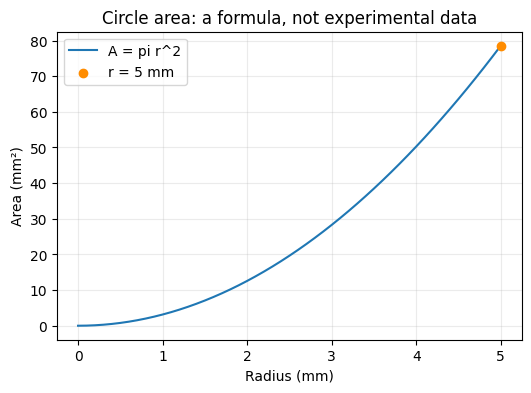

In [3]:
import matplotlib.pyplot as plt

radii_mm = [i / 10 for i in range(51)]
areas_mm2 = [math.pi * r ** 2 for r in radii_mm]
fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(radii_mm, areas_mm2, label="A = pi r^2")
ax.scatter([radius_mm], [area_mm2], color="darkorange", zorder=3,
           label=f"r = {radius_mm:g} mm")
ax.set(xlabel="Radius (mm)", ylabel="Area (mm²)",
       title="Circle area: a formula, not experimental data")
ax.grid(alpha=0.25)
ax.legend()
plt.show()


## 3. 从文件字节读回文字

[课堂样例 `sample.zh.txt`](sample.zh.txt) 使用 UTF-8 保存中文。先读取文件第一行的原始字节，把每个字节打印成 8 位二进制数；再用 UTF-8 解码，观察它们对应的文字。最后把开头两个汉字重新编码，核对每个汉字对应的字节。

In [1]:
from pathlib import Path

candidates = [Path("sample.zh.txt"), Path("演示/sample.zh.txt"),
              Path("lesson01/演示/sample.zh.txt")]
file_path = next((path for path in candidates if path.is_file()), None)
if file_path is None:
    raise FileNotFoundError("请从课程根目录或 lesson01/演示目录运行 Notebook")

raw_bytes = file_path.read_bytes()
first_line_bytes = raw_bytes.splitlines()[0]
print("文件第一行的字节（二进制，每组 8 位）：")
for offset in range(0, len(first_line_bytes), 8):
    print(" ".join(f"{byte:08b}" for byte in first_line_bytes[offset:offset + 8]))

text = first_line_bytes.decode("utf-8")
print("UTF-8 解码后的文字：", text)
for character in text[:2]:
    bits = " ".join(f"{byte:08b}" for byte in character.encode("utf-8"))
    print(f"{bits} → {character}")

文件第一行的字节（二进制，每组 8 位）：
11100110 10100000 10110111 11100101 10010011 10000001 00100000 01001101
00101101 00110000 00110010 00100000 11100110 10011000 10101111 11100100
10111000 10000000 11100100 10111000 10101010 11101000 10011001 10011010
11100110 10011110 10000100 11100111 10100100 10111010 11100100 10111110
10001011 11100011 10000000 10000010
UTF-8 解码后的文字： 样品 M-02 是一个虚构示例。
11100110 10100000 10110111 → 样
11100101 10010011 10000001 → 品
